In [ ]:
import pandas as pd  

def count_rows(rows):
    return len(rows)

df = pd.read_csv("uber_traffic.csv")

cross = df.groupby(["weekday", "hour"]).apply(count_rows) # cara 1
test = df.groupby(["weekday", "hour"]).size() # cara 2
print(test)

weekday    hour
Friday     0       13716
           1        8163
           2        5350
           3        6930
           4        8806
                   ...  
Wednesday  19      47017
           20      47772
           21      44553
           22      32868
           23      18146
Length: 168, dtype: int64


/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_74928/640156614.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cross = df.groupby(["weekday", "hour"]).apply(count_rows)


In [7]:
test = cross.unstack() # untuk mengubah index menjadi kolom
test

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
Friday,13716,8163,5350,6930,8806,13450,23412,32061,31509,25230,...,36206,43673,48169,51961,54762,49595,43542,48323,49409,41260
Monday,6436,3737,2938,6232,9640,15032,23746,31159,29265,22197,...,28157,32744,38770,42023,37000,34159,32849,28925,20158,11811
Saturday,27633,19189,12710,9542,6846,7084,8579,11014,14411,17669,...,31418,38769,43512,42844,45883,41098,38714,43826,47951,43174
Sunday,32877,23015,15436,10597,6374,6169,6596,8728,12128,16401,...,28151,31112,33038,31521,28291,25948,25076,23967,19566,12166
Thursday,9293,5290,3719,5637,8505,14169,27065,37038,35431,27812,...,36699,44442,50560,56704,55825,51907,51990,51953,44194,27764
Tuesday,6237,3509,2571,4494,7548,14241,26872,36599,33934,25023,...,34846,41338,48667,55500,50186,44789,44661,39913,27712,14869
Wednesday,7644,4324,3141,4855,7511,13794,26943,36495,33826,25635,...,35148,43388,50684,55637,52732,47017,47772,44553,32868,18146


In [8]:
test2 = test.stack()
test2

weekday    hour
Friday     0       13716
           1        8163
           2        5350
           3        6930
           4        8806
                   ...  
Wednesday  19      47017
           20      47772
           21      44553
           22      32868
           23      18146
Length: 168, dtype: int64

In [9]:
df

,Date/Time,Lat,Lon,Base,weekday,day,minute,month,hour
0,2014-05-01 00:02:00,40.7521,-73.9914,B02512,Thursday,1,2,5,0
1,2014-05-01 00:06:00,40.6965,-73.9715,B02512,Thursday,1,6,5,0
2,2014-05-01 00:15:00,40.7464,-73.9838,B02512,Thursday,1,15,5,0
3,2014-05-01 00:17:00,40.7463,-74.0011,B02512,Thursday,1,17,5,0
4,2014-05-01 00:17:00,40.7594,-73.9734,B02512,Thursday,1,17,5,0
...,...,...,...,...,...,...,...,...,...
4534322,2014-04-30 23:22:00,40.7640,-73.9744,B02764,Wednesday,30,22,4,23
4534323,2014-04-30 23:26:00,40.7629,-73.9672,B02764,Wednesday,30,26,4,23
4534324,2014-04-30 23:31:00,40.7443,-73.9889,B02764,Wednesday,30,31,4,23
4534325,2014-04-30 23:32:00,40.6756,-73.9405,B02764,Wednesday,30,32,4,23


In [10]:
pivot = pd.pivot_table(df, values="Lon", index="weekday",
                       columns="hour", aggfunc="count")

pivot

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
Friday,13716,8163,5350,6930,8806,13450,23412,32061,31509,25230,...,36206,43673,48169,51961,54762,49595,43542,48323,49409,41260
Monday,6436,3737,2938,6232,9640,15032,23746,31159,29265,22197,...,28157,32744,38770,42023,37000,34159,32849,28925,20158,11811
Saturday,27633,19189,12710,9542,6846,7084,8579,11014,14411,17669,...,31418,38769,43512,42844,45883,41098,38714,43826,47951,43174
Sunday,32877,23015,15436,10597,6374,6169,6596,8728,12128,16401,...,28151,31112,33038,31521,28291,25948,25076,23967,19566,12166
Thursday,9293,5290,3719,5637,8505,14169,27065,37038,35431,27812,...,36699,44442,50560,56704,55825,51907,51990,51953,44194,27764
Tuesday,6237,3509,2571,4494,7548,14241,26872,36599,33934,25023,...,34846,41338,48667,55500,50186,44789,44661,39913,27712,14869
Wednesday,7644,4324,3141,4855,7511,13794,26943,36495,33826,25635,...,35148,43388,50684,55637,52732,47017,47772,44553,32868,18146


<Axes: xlabel='hour', ylabel='weekday'>

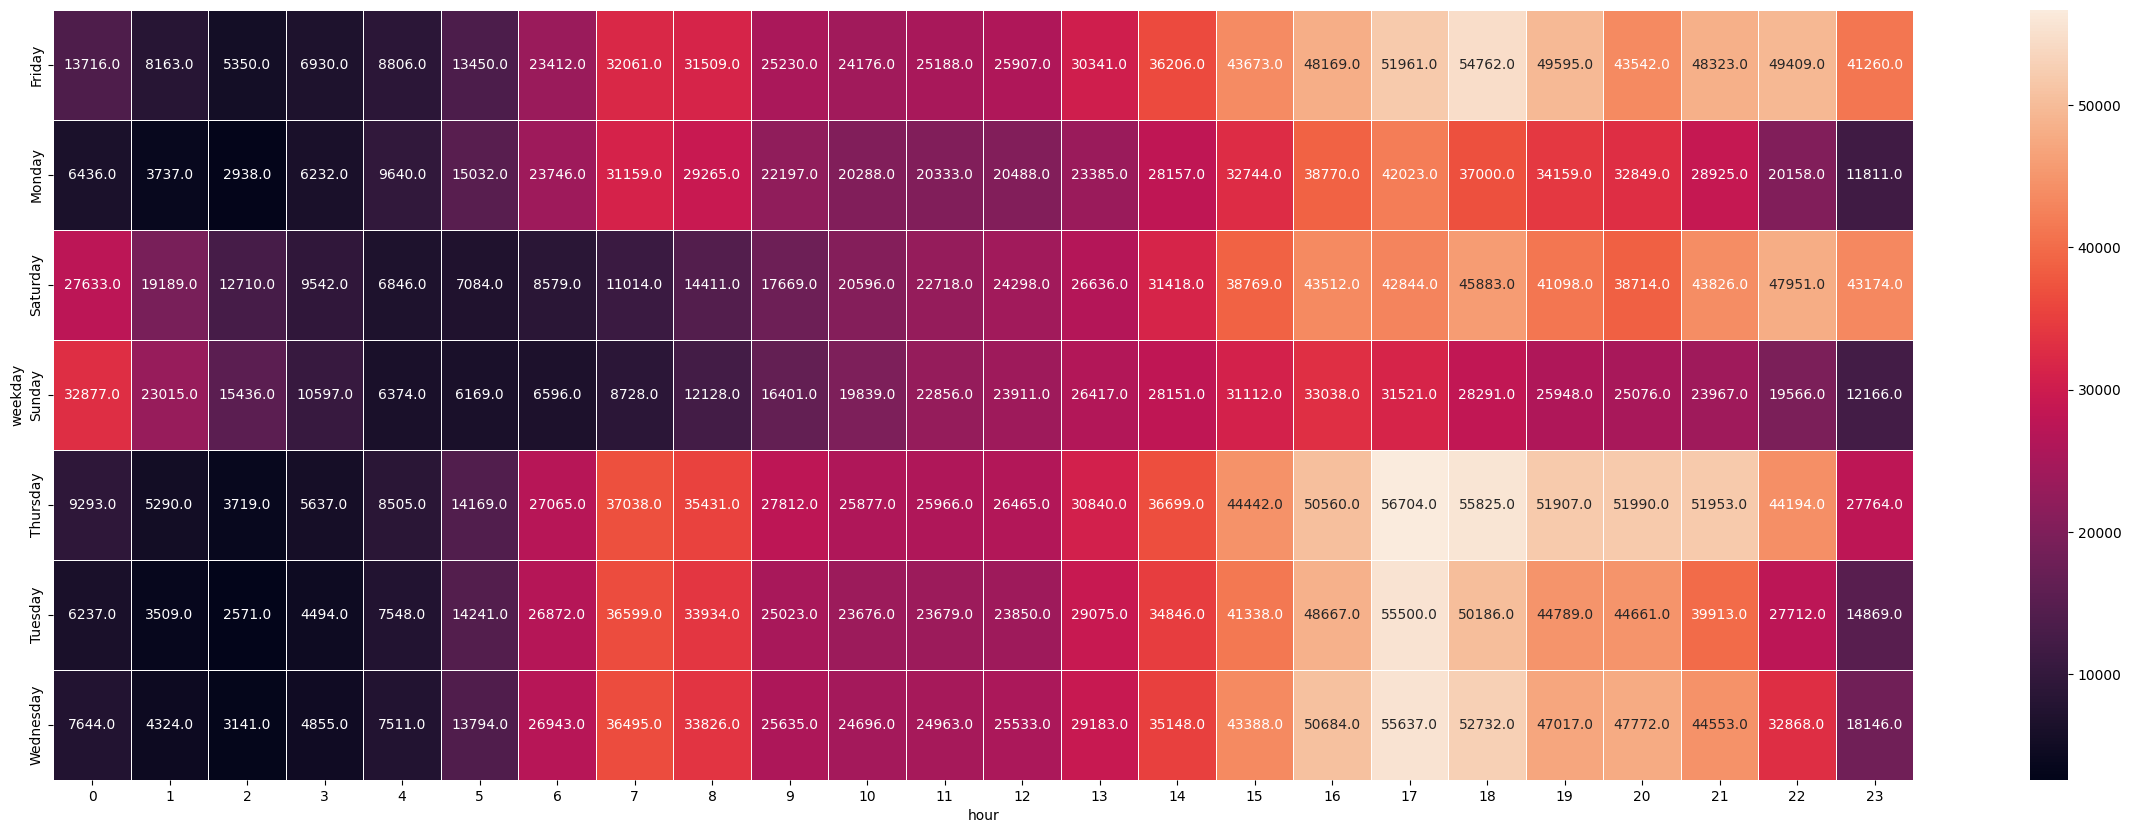

In [11]:
import matplotlib.pyplot as plt 
import seaborn as sns

plt.figure(figsize=(30,10))
sns.heatmap(pivot, annot=True, linewidth=0.5, fmt=".1f")

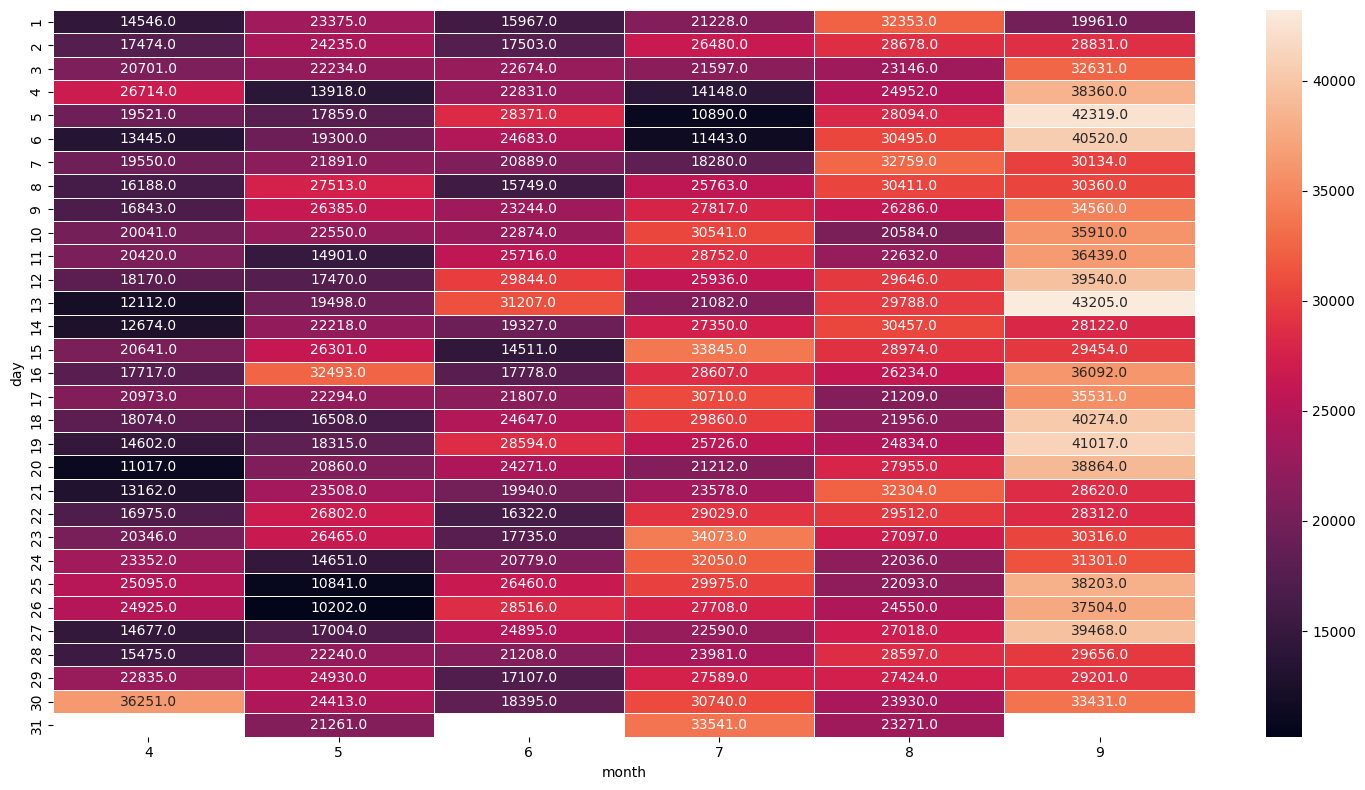

In [12]:
pivot2 = pd.pivot_table(df, values="Base", index="day",
                       columns="month", aggfunc="count")

plt.figure(figsize=(15,8))
sns.heatmap(pivot2, annot=True, linewidth=0.5, fmt=".1f")
plt.tight_layout()
plt.show()

<Axes: xlabel='month', ylabel='weekday'>

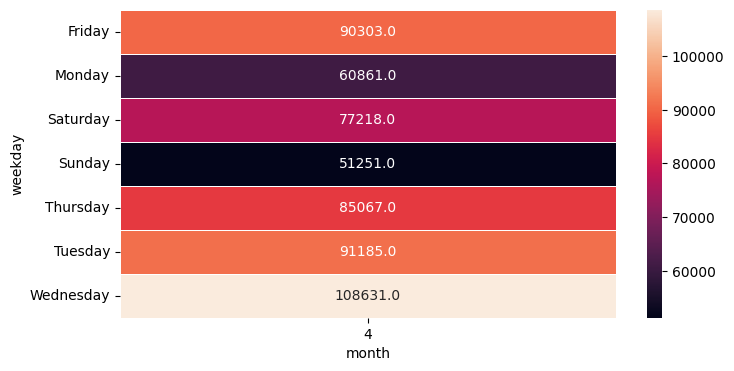

In [13]:
df_day = df[df["month"] == 4]

pivot3 = pd.pivot_table(df_day, values="Base", index="weekday",
                       columns="month", aggfunc="count")

plt.figure(figsize=(8,4))
sns.heatmap(pivot3, annot=True, linewidth=0.5, fmt=".1f")

(40.6, 41.0)

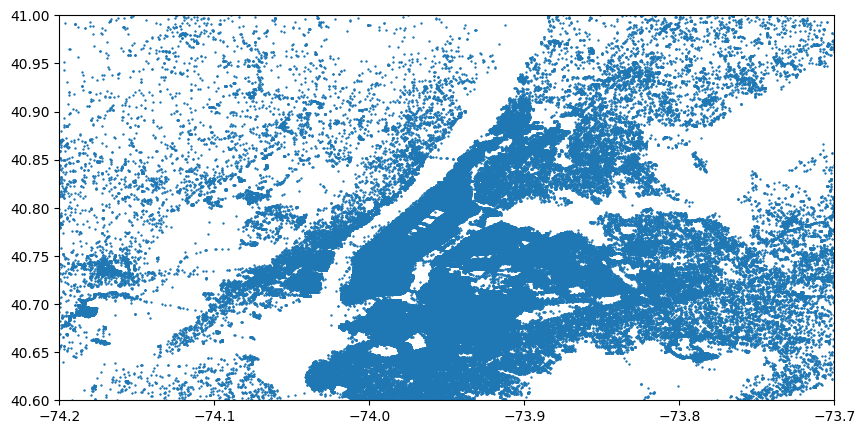

In [14]:
plt.figure(figsize=(10,5))
plt.plot(df["Lon"], df["Lat"], "+", ms = 2)
plt.xlim(-74.2, -73.7)
plt.ylim(40.6, 41)

In [15]:
df_out = df_day[df_day["weekday"] == "Sunday"]
df_out

,Date/Time,Lat,Lon,Base,weekday,day,minute,month,hour
3976776,2014-04-06 00:00:00,40.6547,-74.3033,B02512,Sunday,6,0,4,0
3976777,2014-04-06 00:00:00,40.7356,-74.0006,B02512,Sunday,6,0,4,0
3976778,2014-04-06 00:00:00,40.7421,-74.0041,B02512,Sunday,6,0,4,0
3976779,2014-04-06 00:00:00,40.7401,-74.0053,B02512,Sunday,6,0,4,0
3976780,2014-04-06 00:01:00,40.7368,-73.9877,B02512,Sunday,6,1,4,0
...,...,...,...,...,...,...,...,...,...
4533084,2014-04-27 22:59:00,40.7741,-73.8725,B02764,Sunday,27,59,4,22
4533085,2014-04-27 23:23:00,40.7782,-73.9625,B02764,Sunday,27,23,4,23
4533086,2014-04-27 23:33:00,40.6449,-73.7823,B02764,Sunday,27,33,4,23
4533087,2014-04-27 23:35:00,40.7278,-73.9822,B02764,Sunday,27,35,4,23


In [ ]:
from folium.plugins import HeatMap 
import folium

basemap = folium.Map()

data = df_out.groupby(["Lat", "Lon"])["weekday"].count().reset_index()

heat_data = data[['Lat', 'Lon', 'weekday']].values.tolist()

HeatMap(heat_data).add_to(basemap)
basemap.save("peta_saya.html")

print("Peta berhasil disimpan! Silakan buka file peta_saya.html")

Peta berhasil disimpan! Silakan buka file peta_saya.html


In [ ]:
# assignment

data = pd.read_csv("uber-traffic/uber-raw-data-janjune-15.csv")